# ChemBERTa MLM fine-tuning for masked-molecule prediction

Dataset: QM9 cleaned SELFIES/SMILES. We fine-tune `seyonec/ChemBERTa-zinc-base-v1` with masked language modeling so it learns to predict masked tokens in molecule sequences.


In [1]:
!pip -q install transformers datasets accelerate rdkit-pypi 2>/dev/null
import torch, pandas as pd
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)

2.11.0+cu130 True Tesla T4


In [2]:
import pandas as pd
train = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/train.csv')
val = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/validation.csv')
print(train.shape, val.shape)
print(train['canonical_smiles'].head().tolist())
print('nulls:', train['canonical_smiles'].isna().sum())

(85643, 19) (10705, 19)
['CCCN=c1ocno1', 'NC(=O)N1C(=O)C2CC21', 'c1nnn(C2CC2)n1', 'FC(F)(F)C1C2CC1O2', 'CCCCCCCCC']
nulls: 0


In [3]:
from datasets import Dataset
# Use canonical SMILES as the text field for ChemBERTa
train_ds = Dataset.from_pandas(train[['canonical_smiles']].rename(columns={'canonical_smiles':'text'}))
val_ds = Dataset.from_pandas(val[['canonical_smiles']].rename(columns={'canonical_smiles':'text'}))
print(train_ds, val_ds)

Dataset({
    features: ['text'],
    num_rows: 85643
}) Dataset({
    features: ['text'],
    num_rows: 10705
})


In [4]:
from transformers import AutoTokenizer, AutoModelForMaskedLM, DataCollatorForLanguageModeling, TrainingArguments, Trainer, EarlyStoppingCallback

MODEL = 'seyonec/ChemBERTa-zinc-base-v1'
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForMaskedLM.from_pretrained(MODEL)
print('vocab', tokenizer.vocab_size)

Loading weights:   0%|          | 0/108 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: seyonec/ChemBERTa-zinc-base-v1
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab 767


In [5]:
def tok(batch):
    return tokenizer(batch['text'], truncation=True, max_length=128, padding=False)
train_tok = train_ds.map(tok, batched=True, remove_columns=['text'])
val_tok = val_ds.map(tok, batched=True, remove_columns=['text'])
collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=True, mlm_probability=0.20)

Map:   0%|          | 0/85643 [00:00<?, ? examples/s]

Map:   0%|          | 0/10705 [00:00<?, ? examples/s]

In [6]:
args = TrainingArguments(
    output_dir='/kaggle/working/chemberta-mlm',
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    gradient_accumulation_steps=4,
    num_train_epochs=15,
    learning_rate=2e-5,
    warmup_steps=500,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    fp16=True,
    logging_steps=100,
    report_to='none',
)
trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok, data_collator=collator, callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
trainer.train()
trainer.save_model('/kaggle/working/chemberta-mlm-final')
tokenizer.save_pretrained('/kaggle/working/chemberta-mlm-final')

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,9.446895,1.957512
2,7.019756,1.550611
3,6.032469,1.388967
4,5.665196,1.316701
5,5.459672,1.277577
6,5.218257,1.226806
7,5.087806,1.166849
8,5.015836,1.144491
9,4.894123,1.125815
10,4.752326,1.105419


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (24 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['lm_head.decoder.weight', 'lm_head.decoder.bias'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/chemberta-mlm-final/tokenizer_config.json',
 '/kaggle/working/chemberta-mlm-final/tokenizer.json')

In [7]:
# Inference: mask a token and fill
from transformers import pipeline
fill = pipeline('fill-mask', model='/kaggle/working/chemberta-mlm-final', tokenizer=tokenizer, device=0)
smi = 'CC(=O)Oc1ccccc1C(=O)O'  # aspirin
# mask a position
masked = smi[:5] + tokenizer.mask_token + smi[6:]
print(masked)
print(fill(masked)[:5])

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

CC(=O<mask>Oc1ccccc1C(=O)O
[{'score': 0.9987174272537231, 'token': 13, 'token_str': ')', 'sequence': 'CC(=O)Oc1ccccc1C(=O)O'}, {'score': 0.00017789617413654923, 'token': 281, 'token_str': ')(', 'sequence': 'CC(=O)(Oc1ccccc1C(=O)O'}, {'score': 0.0001544314291095361, 'token': 39, 'token_str': 'C', 'sequence': 'CC(=OCOc1ccccc1C(=O)O'}, {'score': 9.309130837209523e-05, 'token': 295, 'token_str': ')=', 'sequence': 'CC(=O)=Oc1ccccc1C(=O)O'}, {'score': 8.783215162111446e-05, 'token': 272, 'token_str': ')[', 'sequence': 'CC(=O)[Oc1ccccc1C(=O)O'}]


In [8]:
# ---- Test-set accuracy metrics ----
test = pd.read_csv('/kaggle/input/datasets/ssshaun/clean-qm9-dataset-fro-seqligase-project/data/processed/test.csv')
test_ds = Dataset.from_pandas(test[['canonical_smiles']].rename(columns={'canonical_smiles':'text'}))
test_tok = test_ds.map(tok, batched=True, remove_columns=['text'])

# Perplexity + token-level masked accuracy via the Trainer
import math, numpy as np
test_out = trainer.predict(test_tok)
logits = test_out.predictions
labels = test_out.label_ids
# labels == -100 for non-masked positions; compute top-1 accuracy on masked positions
mask = labels != -100
preds = logits.argmax(-1)
acc = (preds[mask] == labels[mask]).mean()
# top-5
top5 = (logits[mask].argsort(-1)[:,-5:] == labels[mask,None]).any(1).mean()
ppl = math.exp(test_out.metrics.get('test_loss', float('nan')))
print(f"Test masked-token accuracy (top-1): {acc:.4f}")
print(f"Test masked-token accuracy (top-5): {top5:.4f}")
print(f"Test perplexity: {ppl:.2f}")
print("metrics:", test_out.metrics)

# Save metrics
import json as _j
with open('/kaggle/working/test_metrics.json','w') as f:
    _j.dump({'masked_token_accuracy_top1': float(acc), 'perplexity': float(ppl), **{k:float(v) for k,v in test_out.metrics.items() if isinstance(v,(int,float))}}, f, indent=2)

Map:   0%|          | 0/10706 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Test masked-token accuracy (top-1): 0.7981
Test masked-token accuracy (top-5): 0.9750
Test perplexity: 2.88
metrics: {'test_loss': 1.0587118864059448, 'test_runtime': 6.0244, 'test_samples_per_second': 1777.105, 'test_steps_per_second': 13.943}


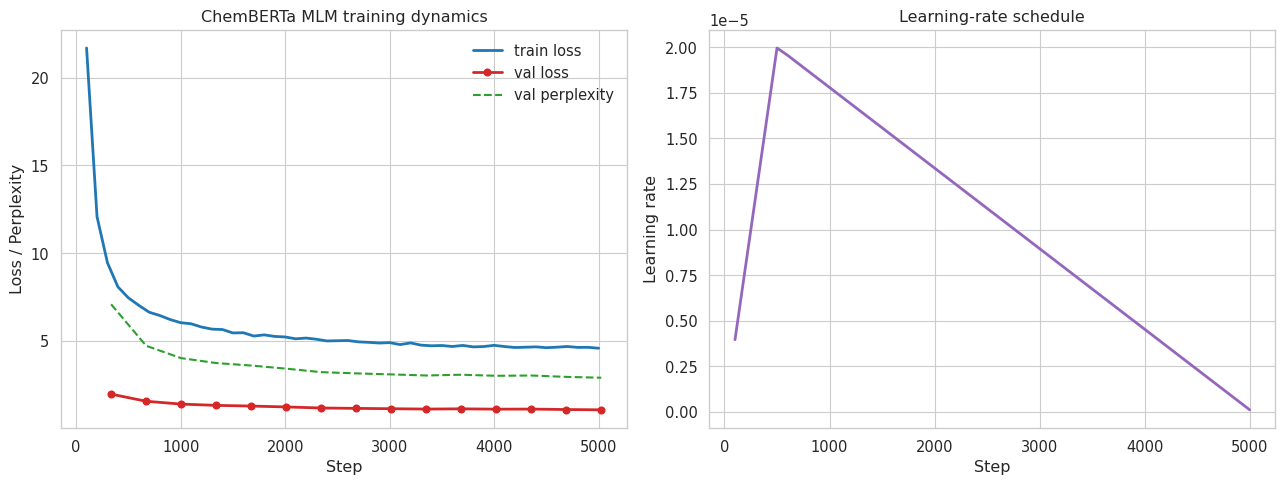

In [9]:
# ---- Research-grade training curves ----
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid', context='paper', font_scale=1.2)
hist = trainer.state.log_history
train_loss = [(h['step'], h['loss']) for h in hist if 'loss' in h and 'eval_loss' not in h]
eval_loss = [(h['step'], h['eval_loss']) for h in hist if 'eval_loss' in h]
fig, ax = plt.subplots(1,2, figsize=(13,5))
if train_loss:
    xs, ys = zip(*train_loss)
    ax[0].plot(xs, ys, color='#1f77b4', lw=2, label='train loss')
if eval_loss:
    xs, ys = zip(*eval_loss)
    ax[0].plot(xs, ys, color='#d62728', lw=2, marker='o', label='val loss')
    ax[0].plot(xs, [math.exp(v) for v in ys], color='#2ca02c', lw=1.5, ls='--', label='val perplexity')
ax[0].set_xlabel('Step'); ax[0].set_ylabel('Loss / Perplexity')
ax[0].set_title('ChemBERTa MLM training dynamics')
ax[0].legend(frameon=False)
# learning rate curve
lr = [(h['step'], h['learning_rate']) for h in hist if 'learning_rate' in h]
if lr:
    xs, ys = zip(*lr)
    ax[1].plot(xs, ys, color='#9467bd', lw=2)
ax[1].set_xlabel('Step'); ax[1].set_ylabel('Learning rate')
ax[1].set_title('Learning-rate schedule')
fig.tight_layout()
fig.savefig('/kaggle/working/training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

In [10]:
import shutil
from IPython.display import FileLink

# Compress the folder
shutil.make_archive('chemberta-mlm-final', 'zip', '/kaggle/working/chemberta-mlm-final')

# Generate a clickable download link
FileLink('chemberta-mlm-final.zip')

/kaggle/working/chemberta-mlm-final.zip